# The U-Net, step by step

Methods 4 and 5 of the project: **U-Net (radar)** and **U-Net (radar + optical)**. This notebook explains
what a U-Net is, how the project feeds it, how it is trained and how it makes a map, then trains a small
demo model in front of you, and finally shows the results of the real, full-size training.

## How to use this notebook

**Read notebook 01 first** (at least Parts 2 to 4: the data, the model inputs, and scoring). This notebook
reuses those ideas without re-explaining them.

**Prerequisites:** the project's virtual environment and the *Python 3 (ipykernel)* kernel (the start files in START_HERE.md set it up), the data
under `data/raw/sen1floods11/`, and the files in `results/`. Keep `src/flood_radar_analytics/unet.py` open
next to the notebook: almost every cell calls a function from it.

**Run order:** top to bottom (*Kernel → Restart & Run All*).

**Runtime:** about 1.5 minutes on an Apple-silicon Mac (M4), using its GPU (`mps`). The demo training (about
1 minute) is the slow part. On a CPU-only machine expect it to be much slower.

**This notebook writes nothing.** In particular it never calls `unet.save_unet`, so `models/` stays as it
is.

**The macOS rule.** This notebook loads **PyTorch** and must never load **LightGBM** (both ship their own
OpenMP runtime; together they crash or freeze; see `src/flood_radar_analytics/__init__.py`). That is why the
U-Net has its own notebook. The first and last cells check it.

## Contents

0. Setup: PyTorch, the GPU, and the pretrained weights
1. Why a pixel needs its neighbours
2. What a U-Net is
3. The inputs
4. From output to probability, and the loss for rare water
5. Random crops, rotations and flips
6. The training loop: batches, epochs, and choosing the best epoch
7. Making a map of a whole chip: tiled inference
8. Train a small demo model, then score it
9. The real results (full run)
10. Recap and exercises

## 0. Setup

**PyTorch** is the deep-learning library. Its basic object is a **tensor**: like a numpy array, but it can
live on a GPU and it can track how it was computed, so that gradients (Part 6) can be calculated.

`unet.device()` picks where the network runs: `mps` (the Apple-silicon GPU, "Metal Performance Shaders")
if available, else an NVIDIA GPU (`cuda`), else the CPU.

**Pretrained weights.** `unet.build_unet` builds the network with `segmentation_models_pytorch` (`smp`) and,
by default, starts its encoder from weights **pretrained on ImageNet** (a large collection of ordinary
photos). `smp` downloads these once from the Hugging Face hub and caches them in
`~/.cache/huggingface/hub`. The next cell tells the Hugging Face library to work **offline** (use the cache,
never the network). If the weights are not in the cache, the cell falls back to random starting weights
(`pretrained=False`, which `build_unet` supports) and says so; everything still runs, the demo just learns
more slowly.

In [1]:
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")   # use cached pretrained weights; never download

import json
import sys
import time
from pathlib import Path

NOTEBOOK_STARTED = time.time()
ROOT = Path.cwd().parent if (Path.cwd().parent / "src").exists() else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from flood_radar_analytics import config, data, evaluation, unet

pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
RESULTS = config.RESULTS_DIR

assert "lightgbm" not in sys.modules, "LightGBM must not be loaded in this notebook (macOS rule)"
DEV = unet.device()
print("torch", torch.__version__, "| device:", DEV)

torch 2.14.1 | device: mps


Now check that the pretrained weights load from the cache. If they do not, replace `unet.build_unet` (only in
this notebook's memory) by a version whose default is `pretrained=False`, because `unet.train_unet` calls
`build_unet(variant)` with the default.

In [2]:
_build_unet_original = unet.build_unet
try:
    _build_unet_original("s1", pretrained=True)
    PRETRAINED = True
    print("ImageNet-pretrained ResNet-34 weights found in the local cache (offline).")
except Exception as err:   # not cached and no network allowed
    PRETRAINED = False
    # unet.train_unet calls build_unet(variant) with the default pretrained=True; make that default False.
    unet.build_unet = lambda variant, pretrained=False: _build_unet_original(variant, pretrained=False)
    print(f"Pretrained weights unavailable ({type(err).__name__}); using random starting weights instead.")

ImageNet-pretrained ResNet-34 weights found in the local cache (offline).


Two picture helpers, the same as in notebook 01:

In [3]:
def show_vv(ax, chip, title="radar VV (dB)"):
    cmap = plt.get_cmap("gray").copy(); cmap.set_bad("red")
    ax.imshow(np.ma.masked_invalid(chip.s1[0]), cmap=cmap, vmin=-25, vmax=0)
    ax.set_title(title); ax.axis("off")


def show_mask(ax, mask, title, label=None):
    img = np.where(mask, 1.0, 0.0)
    if label is not None:
        img = np.where(label == config.NODATA_LABEL, np.nan, img)
    cmap = plt.get_cmap("Blues").copy(); cmap.set_bad("lightgrey")
    ax.imshow(img, cmap=cmap, vmin=0, vmax=1.3); ax.set_title(title); ax.axis("off")


CHIP_NAME = "India_900498_S1Hand.tif"     # the example chip of notebook 01 (official test split)
chip = data.load_chip(CHIP_NAME, with_s2=True)

## 1. Why a pixel needs its neighbours

Look closely at a 96 × 96-pixel corner of the example chip (about 1 km across). On the left the radar, in
the middle the hand label, on the right one row of VV values across the image.

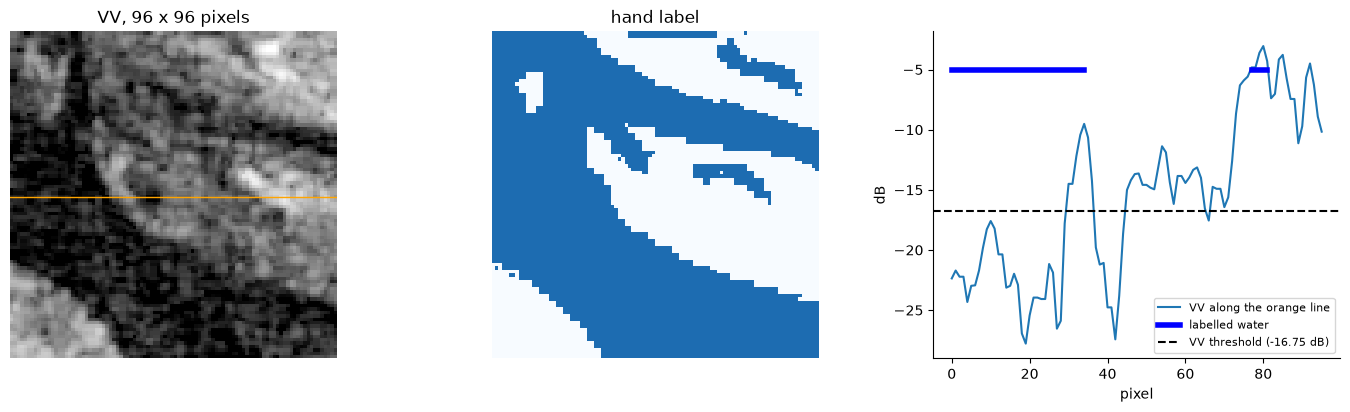

In [4]:
r0, c0, size = 230, 360, 96
crop = chip.s1[0][r0:r0 + size, c0:c0 + size]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
axes[0].imshow(crop, cmap="gray", vmin=-25, vmax=0); axes[0].set_title("VV, 96 x 96 pixels"); axes[0].axis("off")
axes[0].axhline(size // 2, color="orange", lw=1)
show_mask(axes[1], chip.label[r0:r0 + size, c0:c0 + size] == 1, "hand label")
row = r0 + size // 2
axes[2].plot(chip.s1[0][row, c0:c0 + size], label="VV along the orange line")
axes[2].plot(np.where(chip.label[row, c0:c0 + size] == 1, -5, np.nan), "b", lw=4, label="labelled water")
axes[2].axhline(-16.75, color="k", ls="--", label="VV threshold (-16.75 dB)")
axes[2].set_xlabel("pixel"); axes[2].set_ylabel("dB"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

**What to notice:** along a single row, VV jumps up and down by several dB from one pixel to the next
(speckle), on water and on land. Many water pixels poke above the threshold line, and some land dips below
it. A human still sees the water instantly, because we look at **shapes and surroundings**: a long, connected,
darker band is a river, even where single pixels are bright.

LightGBM (notebook 01, Part 7) gets a little of this through hand-made neighbourhood features (means and
standard deviations in 5 × 5 and 15 × 15 windows). A **convolutional neural network** goes much further:
it *learns* which neighbourhood patterns matter, at many scales at once.

## 2. What a U-Net is

### 2.1 The building block: a convolution

A **convolution** slides a small grid of numbers (a **filter** or **kernel**, for example 3 × 3) over the
image. At each position, the output pixel is the weighted sum of the input pixels under the filter. With
all nine weights equal to 1/9, a 3 × 3 convolution is exactly a local mean, the same idea as LightGBM's
`vv_mean_5` feature, just smaller:

pixel (100, 100): conv output -11.076, numpy 3x3 mean -11.076


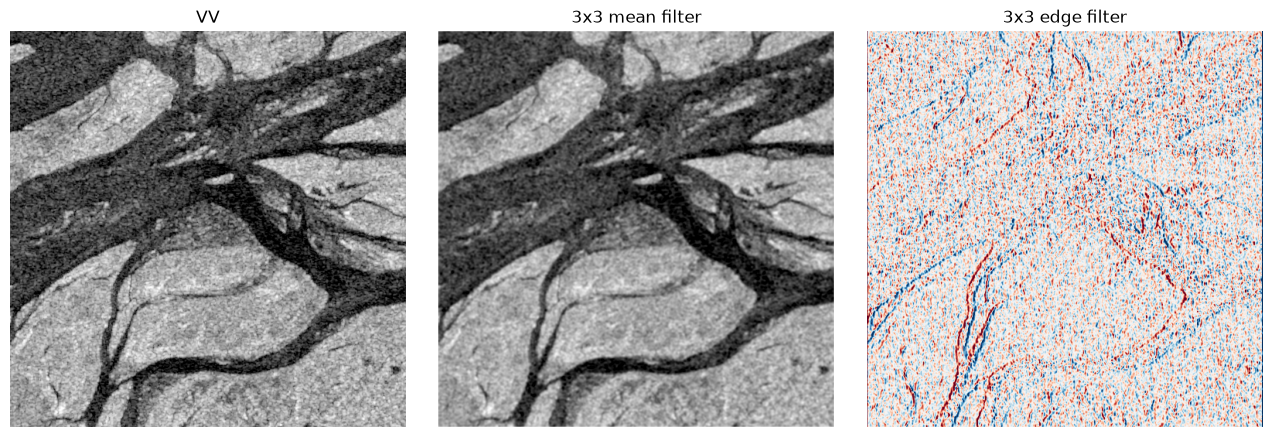

In [5]:
vv = torch.from_numpy(np.nan_to_num(np.clip(chip.s1[0], -30, 5), nan=-15.0))[None, None]  # (batch, channel, H, W)
mean_filter = torch.full((1, 1, 3, 3), 1 / 9)
edge_filter = torch.tensor([[[[-1.0, 0, 1], [-2, 0, 2], [-1, 0, 1]]]])   # responds to left-right changes
smoothed = torch.nn.functional.conv2d(vv, mean_filter, padding=1)[0, 0]
edges = torch.nn.functional.conv2d(vv, edge_filter, padding=1)[0, 0]

print(f"pixel (100, 100): conv output {smoothed[100, 100]:.3f}, numpy 3x3 mean {vv[0, 0, 99:102, 99:102].mean():.3f}")
fig, axes = plt.subplots(1, 3, figsize=(13, 4.3))
for ax, img, title, kw in ((axes[0], vv[0, 0], "VV", dict(cmap="gray", vmin=-25, vmax=0)),
                           (axes[1], smoothed, "3x3 mean filter", dict(cmap="gray", vmin=-25, vmax=0)),
                           (axes[2], edges, "3x3 edge filter", dict(cmap="RdBu", vmin=-30, vmax=30))):
    ax.imshow(img, **kw); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()

In a neural network the filter weights are **not** chosen by hand: they start random (or pretrained) and are
**learned** from the labels during training. A network stacks many convolution **layers**, each with dozens
or hundreds of filters, with a simple non-linear step between them (ReLU: negative values become 0). The
first layers learn simple things like edges and smoothing; deeper layers combine them into "shoreline",
"river channel", "flooded field".

### 2.2 Encoder, decoder, skip connections

A U-Net has two halves, drawn as a U:

```
input 512 x 512 (3 or 10 channels)                                       output 512 x 512 (1 channel)
  |                                                                                         ^
  v                                                                                         |
[enc 1/2  ] ------------------------- skip: copy features across ----------------> [dec 1/2  ]
  |                                                                                         ^
  v                                                                                         |
  [enc 1/4  ] ---------------------------- skip ------------------------------> [dec 1/4  ]
    |                                                                                   ^
    v                                                                                   |
    [enc 1/8  ] ------------------------- skip -------------------------> [dec 1/8  ]
      |                                                                           ^
      v                                                                           |
      [enc 1/16 ] ------------------------ skip -----------------> [dec 1/16 ]
        |                                                                ^
        v                                                                |
        [enc 1/32 ] ---------------- bottom: coarse, wide view ----------+
```

- The **encoder** (left, going down) applies convolutions and repeatedly **halves the resolution**. Each
  step down, one feature pixel summarises a bigger area of the image (its **receptive field** grows), so the
  deepest features "see" hundreds of metres of context, but only coarsely. Here the encoder is a
  **ResNet-34**, a well-known image network with 34 layers.
- The **decoder** (right, going up) **upsamples** step by step back to full resolution and ends with one
  output number per pixel.
- The **skip connections** (horizontal arrows) copy the encoder's features at each resolution straight
  across to the decoder. Without them, fine detail lost while shrinking (exact shorelines, narrow channels)
  could not be recovered. With them, the decoder combines "what is this area?" (from the bottom) with
  "where exactly is the edge?" (from the skips).

Text version of the diagram: input → five encoder stages at 1/2, 1/4, 1/8, 1/16, 1/32 resolution → decoder
stages back up at 1/16 ... 1/2 and full size, each decoder stage also receiving the encoder features of the
same size → one output value per pixel.

### 2.3 The project's U-Net in code

`unet.build_unet(variant)` is three lines: `smp.Unet(encoder_name="resnet34", encoder_weights="imagenet",
in_channels=..., classes=1)`. `in_channels` is 3 for `"s1"` and 10 for `"s1s2"` (`config.INPUT_CHANNELS`);
`classes=1` means one output map (water). Let us push a dummy input through it and watch the shapes:

In [6]:
net = unet.build_unet("s1", pretrained=PRETRAINED).eval()
n_params = sum(p.numel() for p in net.parameters())
print(f"U-Net (radar): {n_params:,} learnable numbers (parameters)")

dummy = torch.zeros(1, 3, 256, 256)        # a batch of 1 image, 3 channels, 256 x 256 pixels
with torch.no_grad():
    features = net.encoder(dummy)          # list: the input, then one feature map per encoder stage
    out = net(dummy)
for i, f in enumerate(features):
    print(f"encoder output {i}: {tuple(f.shape)}   (resolution 1/{256 // f.shape[-1]})")
print("network output:", tuple(out.shape))

U-Net (radar): 24,436,369 learnable numbers (parameters)
encoder output 0: (1, 3, 256, 256)   (resolution 1/1)
encoder output 1: (1, 64, 128, 128)   (resolution 1/2)
encoder output 2: (1, 64, 64, 64)   (resolution 1/4)
encoder output 3: (1, 128, 32, 32)   (resolution 1/8)
encoder output 4: (1, 256, 16, 16)   (resolution 1/16)
encoder output 5: (1, 512, 8, 8)   (resolution 1/32)
network output: (1, 1, 256, 256)


**What to notice:** the spatial size halves at each stage (256 → 128 → ... → 8) while the number of
channels (feature maps) grows (64 → ... → 512): fewer, coarser pixels, each described by more numbers. The
output is back at 256 × 256 with one channel: one score per input pixel. Over 24 million parameters is
small for modern networks but huge compared with LightGBM, which is why the U-Net needs a GPU.

### 2.4 Pretrained weights, and 10 input channels

ImageNet weights were learned on 3-channel colour photos. For the radar U-Net (3 channels) they are used
as they are. For the radar + optical U-Net (10 channels), `smp` adapts the **first** convolution (see
`patch_first_conv` in `segmentation_models_pytorch/encoders/_utils.py`): channel *i* gets a copy of the
pretrained weights of RGB channel *i mod 3*, and all weights are scaled by 3/10, so the layer's output stays
on the same scale. The rest of the network is unchanged. Radar is not a photo, but edge and texture filters
learned on photos are still a much better starting point than random numbers.

In [7]:
net10 = unet.build_unet("s1s2", pretrained=PRETRAINED)
w3, w10 = net.encoder.conv1.weight.detach(), net10.encoder.conv1.weight.detach()
print("first-layer weights: s1", tuple(w3.shape), " s1s2", tuple(w10.shape))
if PRETRAINED:
    print("channel 3 is a copy of channel 0:          ", torch.allclose(w10[:, 3], w10[:, 0]))
    print("channel 0 equals RGB channel 0 times 3/10:  ", torch.allclose(w10[:, 0], w3[:, 0] * 3 / 10))
del net10

first-layer weights: s1 (64, 3, 7, 7)  s1s2 (64, 10, 7, 7)
channel 3 is a copy of channel 0:           True
channel 0 equals RGB channel 0 times 3/10:   True


## 3. The inputs

The U-Nets take exactly the inputs built in notebook 01, Part 3: `data.model_input(chip, variant)`, the
clipped radar channels and VH − VV (plus, for `"s1s2"`, six optical bands and NDWI), **normalised** with the
training-split means and standard deviations, NaN replaced by 0. To feed the network, the numpy array becomes
a tensor, and a **batch** dimension is added in front: networks always process a batch of images,
shape (batch, channels, height, width).

In [8]:
for variant in ("s1", "s1s2"):
    x = data.model_input(chip, variant)
    print(f"{variant:<5} channels {config.INPUT_CHANNELS[variant]}")
    print(f"      numpy {x.shape} {x.dtype} -> tensor {tuple(torch.from_numpy(x)[None].shape)}")

s1    channels ['vv', 'vh', 'ratio']
      numpy (3, 512, 512) float32 -> tensor (1, 3, 512, 512)
s1s2  channels ['vv', 'vh', 'ratio', 'B2', 'B3', 'B4', 'B8', 'B11', 'B12', 'ndwi']
      numpy (10, 512, 512) float32 -> tensor (1, 10, 512, 512)


Both variants share the same code path everywhere (training, validation, the full-run scripts), so the
network always sees inputs prepared the same way.

## 4. From output to probability, and the loss for rare water

### 4.1 Logits and the sigmoid

The network's output numbers are **logits**: any real number, positive meaning "water" and negative "not
water". The **sigmoid** function `1 / (1 + e^(−z))` squashes a logit `z` into a probability between 0 and 1.
The project calls a pixel water when the probability is at least 0.5 (`unet.unet_predictor`'s
`threshold=0.5`), which is the same as logit ≥ 0.

In [9]:
logits = torch.tensor([-4.0, -1.0, 0.0, 1.0, 4.0])
print("logit      :", logits.tolist())
print("probability:", [round(float(p), 3) for p in torch.sigmoid(logits)])

logit      : [-4.0, -1.0, 0.0, 1.0, 4.0]
probability: [0.018, 0.269, 0.5, 0.731, 0.982]


### 4.2 The loss: BCE + Dice (`unet.BceDiceLoss`)

Training needs a single number that says how wrong the network is, the **loss**; training lowers it.
`BceDiceLoss` adds two parts, computed only over pixels whose label is not −1:

- **BCE** (binary cross-entropy): the average over pixels of `−log(probability given to the right answer)`.
  It punishes confident wrong answers hard and gives smooth, stable gradients. But it is an *average over
  pixels*, and about 90% of pixels are land, so a network can get a fairly low BCE by being good at land and
  mediocre at water.
- **Soft Dice**: `1 − (2·Σ p·t + 1) / (Σ p + Σ t + 1)`, where `p` is the predicted probability and `t` the
  label (1 water, 0 land). It is a smooth version of the F1 score (a close cousin of IoU) and only looks at
  water, predicted and real, so the huge number of easy land pixels cannot dilute it. (The `+ 1` avoids
  dividing by zero.)

A toy example: 1,000 pixels, 95 of them water (9.5%, like the training split). Compare a lazy prediction
("fairly sure it's all land") with a decent one:

In [10]:
torch.manual_seed(0)
target = torch.zeros(1000); target[:95] = 1.0
lazy = torch.full((1000,), -2.0)                                   # p = 0.12 everywhere
decent = torch.where(target == 1, 1.5, -2.5) + 0.8 * torch.randn(1000)


def parts(logit, t):
    bce = torch.nn.functional.binary_cross_entropy_with_logits(logit, t)
    p = torch.sigmoid(logit)
    dice = 1 - (2 * (p * t).sum() + 1) / (p.sum() + t.sum() + 1)
    return bce.item(), dice.item(), unet.BceDiceLoss()(logit, t).item()


pd.DataFrame([parts(lazy, target), parts(decent, target)], columns=["BCE", "Dice", "BCE + Dice (project)"],
             index=["lazy: all land", "decent"])

,BCE,Dice,BCE + Dice (project)
lazy: all land,0.317,0.890,1.207
decent,0.120,0.414,0.534


**What to notice:** the lazy prediction's BCE (about 0.32) is not alarming, because it is an average
dominated by the 905 land pixels, which the lazy prediction gets roughly right. Its Dice (about 0.89) is close
to 1, the worst value, because it finds almost no water. Adding Dice makes "ignore the water"
expensive. The project's loss equals BCE + Dice, as the last column shows.

Pixels with label −1 are skipped by the loss, just as the scores skip them:

In [11]:
t = torch.tensor([1.0, 0.0, -1.0])
print("loss, -1 pixel predicted 'water':", round(unet.BceDiceLoss()(torch.tensor([3.0, -3.0, 50.0]), t).item(), 4))
print("loss, -1 pixel predicted 'land': ", round(unet.BceDiceLoss()(torch.tensor([3.0, -3.0, -50.0]), t).item(), 4))

loss, -1 pixel predicted 'water': 0.0802
loss, -1 pixel predicted 'land':  0.0802


## 5. Random crops, rotations and flips (`unet.ChipDataset`)

`ChipDataset(names, variant, augment=True)` loads every chip's `model_input` and label into memory once, then,
each time a chip is requested, returns a **random 256 × 256 crop**, rotated by a random multiple of 90° and
flipped left-right half the time. The label is cut, rotated and flipped in exactly the same way, so it still
matches the pixels. This is **data augmentation**:

- every epoch the network sees different crops of the same chips, so it cannot simply memorise them;
- water looks like water whichever way up the image is, and rotations and flips teach that for free;
- 256-pixel crops take a quarter of the memory of full chips, so more fit in a batch.

Four draws of the same chip:

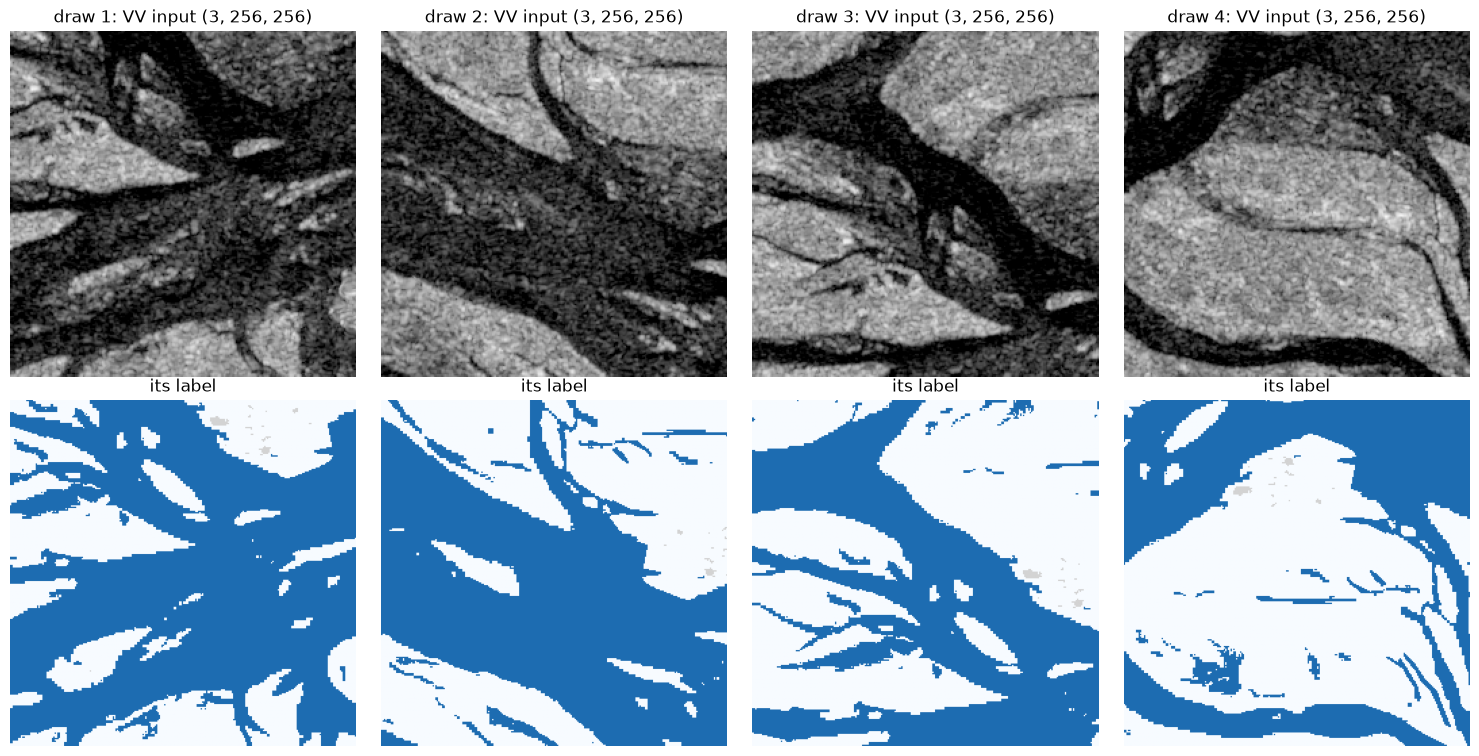

without augment, an item is the full chip: (3, 512, 512)


In [12]:
ds = unet.ChipDataset([CHIP_NAME], "s1", augment=True)
fig, axes = plt.subplots(2, 4, figsize=(15, 7.6))
for k in range(4):
    x, y = ds[0]
    axes[0, k].imshow(x[0], cmap="gray", vmin=-3, vmax=3); axes[0, k].set_title(f"draw {k + 1}: VV input {tuple(x.shape)}")
    axes[0, k].axis("off")
    show_mask(axes[1, k], y.numpy() == 1, "its label", y.numpy())
plt.tight_layout(); plt.show()
print("without augment, an item is the full chip:", tuple(unet.ChipDataset([CHIP_NAME], "s1")[0][0].shape))

## 6. The training loop (`unet.train_unet`)

Read `train_unet` in `unet.py` with this list next to it:

1. `torch.manual_seed(config.RANDOM_SEED)`: fixed random starting point.
2. Build the U-Net and move it to the device (`.to(dev)`).
3. A `DataLoader` wraps the `ChipDataset`: it shuffles the chips and groups them into **batches** of 8 crops.
4. The **optimizer**, AdamW (learning rate 3 × 10⁻⁴, weight decay 10⁻⁴), is the rule for changing the weights.
   A **cosine schedule** lowers the learning rate smoothly to almost 0 by the last epoch: big steps first,
   fine adjustments at the end.
5. For each **epoch** (one pass over all training chips) and each batch:
   - **forward pass**: `net(x)` gives logits for every pixel of the 8 crops;
   - compute the loss (`BceDiceLoss`);
   - **backward pass**: `loss.backward()` computes, for each of the 24 million weights, the **gradient**:
     which direction to nudge that weight to lower the loss;
   - `optimizer.step()` nudges all the weights a little in that direction. This is **gradient descent**.
6. After each epoch, switch to evaluation mode and compute the pooled water IoU on the **validation** chips
   (full chips, using the tiled inference of Part 7 via `evaluation.evaluate`).
7. Keep a copy of the weights from the epoch with the best validation IoU, and return that model with the
   history of every epoch.

Why step 7: a network can keep lowering its training loss while getting worse on new chips (**overfitting**:
memorising the training chips instead of learning water). The validation chips were never trained on, so the
best validation epoch is the best guess for new chips. In the full run (`scripts/train.py`) the validation
chips are the official *valid* split; in leave-one-event-out (`scripts/cross_event.py`) they are a random 10%
of the *training* floods, so the held-out flood is never used to pick anything.

## 7. Making a map of a whole chip: tiled inference (`unet.predict_probability`)

At prediction time the network sees full chips, not crops. `predict_probability(net, x, tile=512)` works for an
input of any size:

- it pads the image by **reflection** (mirror copies of the edge), then slides a 512 × 512 window over it in
  steps of 448 pixels (`step = tile − 2 × margin`, with `margin = 32`);
- for each window it runs the network, applies the sigmoid, and keeps only the **centre** of the window,
  dropping a 32-pixel margin, because pixels near a window's edge have less context and are less reliable;
- the kept centres tile the whole image without gaps.

For one 512 × 512 chip that means 4 windows. Here they are, drawn over the chip (each window's kept centre is
the filled area):

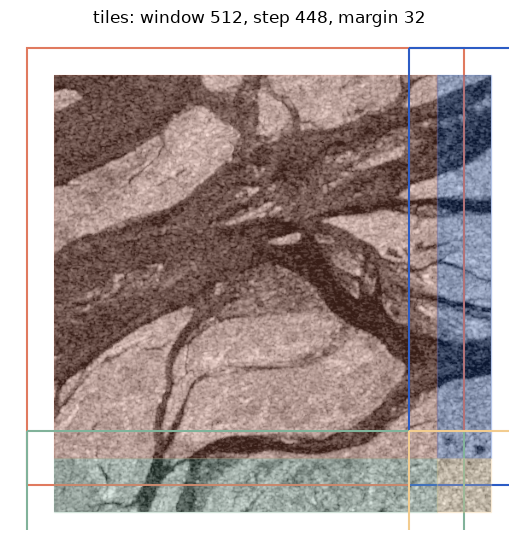

windows per chip: 4


In [13]:
margin, tile = 32, 512
step = tile - 2 * margin
fig, ax = plt.subplots(figsize=(5.5, 5.5))
show_vv(ax, chip, f"tiles: window {tile}, step {step}, margin {margin}")
colors = ["#e07a5f", "#2c5cc5", "#81b29a", "#f2cc8f"]
i = 0
for top in range(0, 512, step):
    for left in range(0, 512, step):
        h, w = min(step, 512 - top), min(step, 512 - left)
        ax.add_patch(plt.Rectangle((left - 0.5, top - 0.5), w, h, color=colors[i], alpha=0.25))
        ax.add_patch(plt.Rectangle((left - margin - 0.5, top - margin - 0.5), tile, tile, fill=False,
                                   ec=colors[i], lw=1.5))
        i += 1
ax.set_xlim(-margin - 20, 512 + 20); ax.set_ylim(512 + 20, -margin - 20)
plt.tight_layout(); plt.show()
print("windows per chip:", i)

(The window outlines start 32 pixels outside the chip, in the mirrored padding.) `unet.unet_predictor(net,
variant)` wraps everything into the usual predictor: `chip → model_input → predict_probability → ≥ 0.5`.

## 8. Train a small demo model, then score it

The real models were trained in `scripts/train.py` for 30 epochs on all 252 training chips (about 30 minutes
for both U-Nets), and in `scripts/cross_event.py` 22 more times (about 4 hours). Here we train the
**radar + optical** U-Net on a **subset**: 64 random training chips for 8 epochs, validating on 24 random
validation chips, so that you can watch training happen in about a minute. We call the project's own
`unet.train_unet` unchanged; only the lists of chips and the number of epochs are smaller.

We pick the radar + optical variant because the full run's `results/benchmark.json` stores its full training
curve to compare against. *(slow, about 60 to 90 s)*

In [14]:
rng = np.random.default_rng(config.RANDOM_SEED)
demo_train = sorted(rng.choice(data.split_names("train"), size=64, replace=False))
demo_valid = sorted(rng.choice(data.split_names("valid"), size=24, replace=False))
print(f"demo: {len(demo_train)} training chips, {len(demo_valid)} validation chips, device {DEV}")

t0 = time.time()
demo_net, demo_history = unet.train_unet(demo_train, demo_valid, "s1s2", epochs=8)
print(f"trained in {time.time() - t0:.0f} s")

demo: 64 training chips, 24 validation chips, device mps


  epoch  1/8  loss 1.5660  valid IoU 0.1341


  epoch  2/8  loss 1.2247  valid IoU 0.2171


  epoch  3/8  loss 1.2006  valid IoU 0.2517


  epoch  4/8  loss 1.1741  valid IoU 0.2826


  epoch  5/8  loss 1.0736  valid IoU 0.3454


  epoch  6/8  loss 1.0641  valid IoU 0.4921


  epoch  7/8  loss 1.0283  valid IoU 0.5248


  epoch  8/8  loss 1.0008  valid IoU 0.5201
trained in 55 s


Each printed line is one epoch: the average training loss and the pooled IoU on the 24 validation chips.
`train_unet` returned the network with the weights of the best epoch. Now compare the demo's curve with the
full run's (stored in `results/benchmark.json` under `history`). The full run's radar-only history is `null`:
that model was reused from an earlier training with `--reuse-existing`, which does not re-record the curve.

full-run histories stored: {'s1': None, 's1s2': 30}


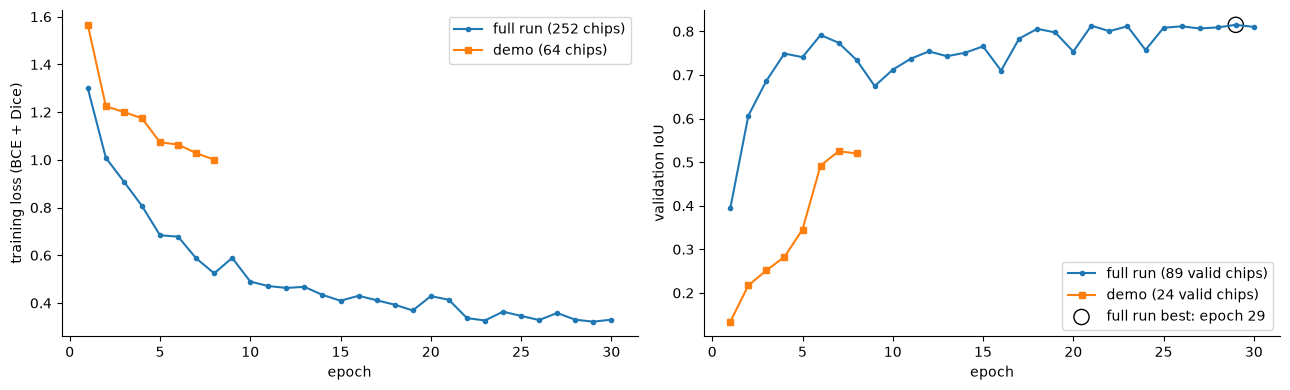

demo best epoch 7: valid IoU 0.525
full-run best epoch 29: valid IoU 0.815


In [15]:
bench = json.loads((RESULTS / "benchmark.json").read_text())
full = pd.DataFrame(bench["history"]["s1s2"])
demo = pd.DataFrame(demo_history)
print("full-run histories stored:", {k: (len(v) if v else v) for k, v in bench["history"].items()})

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(full["epoch"], full["train_loss"], "o-", ms=3, label="full run (252 chips)")
axes[0].plot(demo["epoch"], demo["train_loss"], "s-", ms=4, label="demo (64 chips)")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("training loss (BCE + Dice)"); axes[0].legend()
axes[1].plot(full["epoch"], full["valid_iou"], "o-", ms=3, label="full run (89 valid chips)")
axes[1].plot(demo["epoch"], demo["valid_iou"], "s-", ms=4, label="demo (24 valid chips)")
best_full = full.loc[full["valid_iou"].idxmax()]
axes[1].scatter([best_full["epoch"]], [best_full["valid_iou"]], s=120, facecolors="none", edgecolors="k",
                label=f"full run best: epoch {int(best_full['epoch'])}")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("validation IoU"); axes[1].legend()
plt.tight_layout(); plt.show()
best_demo = demo.loc[demo["valid_iou"].idxmax()]
print(f"demo best epoch {int(best_demo['epoch'])}: valid IoU {best_demo['valid_iou']:.3f}")
print(f"full-run best epoch {int(best_full['epoch'])}: valid IoU {best_full['valid_iou']:.3f}")

**What to notice**

- In the full run, validation IoU climbs steeply over the first few epochs and then creeps up slowly; its
  best epoch was 29 of 30 (validation IoU 0.815).
- The demo's curve is still rising at the end (about 0.52 at epochs 7 and 8): it saw a quarter of the
  chips for about a quarter as many epochs and had not finished learning. `train_unet` still returned the
  best epoch it saw (epoch 7).
- The two validation IoUs are on different chip sets (24 vs 89 chips), so compare the shapes of the curves
  rather than the exact values. Training on a GPU is not perfectly repeatable, so your demo numbers can differ slightly
from the ones saved in this notebook.

### 8.1 The demo model on the example chip

demo U-Net on India_900498_S1Hand.tif: IoU 0.718  precision 0.742  recall 0.957


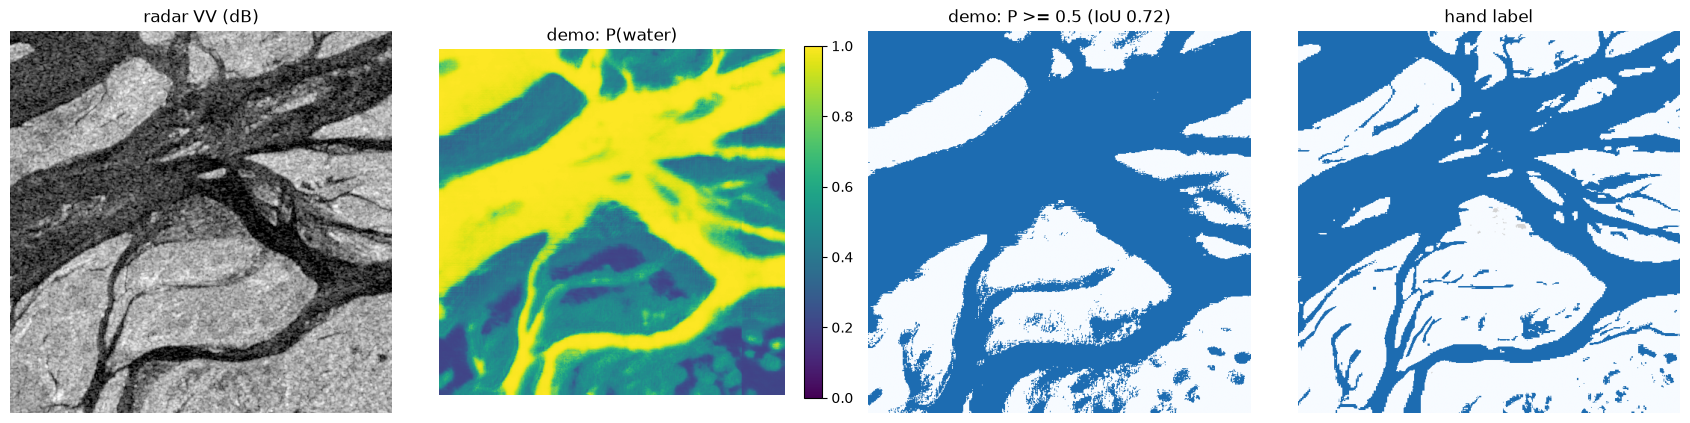

In [16]:
x = data.model_input(chip, "s1s2")
prob = unet.predict_probability(demo_net, x)
demo_mask = unet.unet_predictor(demo_net, "s1s2")(chip)
c = evaluation.Confusion().add(demo_mask, chip.label)
print(f"demo U-Net on {CHIP_NAME}: IoU {c.iou:.3f}  precision {c.precision:.3f}  recall {c.recall:.3f}")

fig, axes = plt.subplots(1, 4, figsize=(17, 4.4))
show_vv(axes[0], chip)
im = axes[1].imshow(prob, cmap="viridis", vmin=0, vmax=1); axes[1].set_title("demo: P(water)"); axes[1].axis("off")
fig.colorbar(im, ax=axes[1], fraction=0.046)
show_mask(axes[2], demo_mask, f"demo: P >= 0.5 (IoU {c.iou:.2f})")
show_mask(axes[3], chip.label == 1, "hand label", chip.label)
plt.tight_layout(); plt.show()

**What to notice:** the demo finds almost all the water (recall about 0.96) but also calls a lot of land
water (precision about 0.74): it has not yet learned where water *stops*. Compare with notebook 01 on the
same chip: LightGBM trained on all training chips had the opposite balance (precision 0.93, recall 0.75).

### 8.2 Score the demo on the official test split

The same scoring as for every other method: `evaluation.evaluate` over the 90 test chips, loaded with the
optical bands (`with_s2=True`). *(about 30 s)*

In [17]:
t0 = time.time()
test_names = data.split_names("test")
demo_eval = evaluation.evaluate({"demo": unet.unet_predictor(demo_net, "s1s2")}, test_names, with_s2=True)["demo"]
full_test = bench["splits"]["test"]["U-Net (radar + optical)"]["pooled"]
print(f"scored {len(test_names)} chips in {time.time() - t0:.0f} s")
pd.DataFrame({"demo (64 chips, 8 epochs)": demo_eval.pooled.as_dict(),
              "full run (252 chips, 30 epochs)": full_test}).T[["IoU", "precision", "recall"]]

scored 90 chips in 17 s


,IoU,precision,recall
"demo (64 chips, 8 epochs)",0.629,0.663,0.923
"full run (252 chips, 30 epochs)",0.830,0.923,0.892


**What to notice:** after about a minute of training on 64 chips, the demo scores a test IoU of about 0.63,
already level with LightGBM trained on all 252 chips (0.64 in notebook 01; VV threshold 0.46, Otsu 0.55). It
still over-predicts water (precision about 0.66, recall about 0.92). The full training reaches 0.83 with
precision and recall both around 0.9: more data and more epochs pay off for a network this size.

## 9. The real results (full run)

The trained weights of the full run are not kept in the repository (`models/` is empty: the app does not
need them, it reads `results/`). `scripts/train.py` would recreate them with `unet.save_unet`, and
`unet.load_unet` would load them. The results of those trainings are all in `results/`.

### 9.1 The official split (`results/benchmark.json`)

In [18]:
METHODS = ["VV threshold", "Authors' Otsu", "LightGBM (radar + texture)", "U-Net (radar)", "U-Net (radar + optical)"]
rows = {}
for m in METHODS:
    for split in ("valid", "test", "bolivia"):
        d = bench["splits"][split][m]["pooled"]
        rows[(m, split)] = {"IoU": d["IoU"], "precision": d["precision"], "recall": d["recall"]}
pd.DataFrame(rows).T.unstack()["IoU"][["valid", "test", "bolivia"]].loc[METHODS]

,valid,test,bolivia
VV threshold,0.465,0.464,0.441
Authors' Otsu,0.507,0.554,0.718
LightGBM (radar + texture),0.600,0.637,0.405
U-Net (radar),0.638,0.672,0.597
U-Net (radar + optical),0.815,0.830,0.811


Precision and recall on the test split show *how* each method errs (false alarms vs missed water):

In [19]:
pd.DataFrame({m: bench["splits"]["test"][m]["pooled"] for m in METHODS}).T[["IoU", "precision", "recall"]]

,IoU,precision,recall
VV threshold,0.464,0.771,0.538
Authors' Otsu,0.554,0.682,0.748
LightGBM (radar + texture),0.637,0.887,0.693
U-Net (radar),0.672,0.818,0.789
U-Net (radar + optical),0.830,0.923,0.892


**What to notice:** on the familiar test chips the radar U-Net (0.67) edges out LightGBM (0.64), and adding
optical bands lifts the U-Net to 0.83, the biggest single jump in the table, with precision and recall both
around 0.9.

### 9.2 New floods: leave-one-event-out (`results/cross_event.json`)

Each flood scored by U-Nets trained on the other ten (22 trainings in total). Pooled over all 11 floods as in
notebook 01, Part 8.4:

In [20]:
cross = json.loads((RESULTS / "cross_event.json").read_text())
iou_of = lambda c: c["tp"] / max(c["tp"] + c["fp"] + c["fn"], 1)
held_out = pd.DataFrame({e: {m: iou_of(cross["events"][e][m]) for m in METHODS} for e in config.EVENTS}).T
held_out["optical gain"] = held_out["U-Net (radar + optical)"] - held_out["U-Net (radar)"]
held_out = held_out.sort_values("optical gain", ascending=False)
pooled = {m: iou_of({k: sum(cross["events"][e][m][k] for e in config.EVENTS) for k in ("tp", "fp", "fn")})
          for m in METHODS}
held_out.loc["Pooled (all 11)"] = {**pooled, "optical gain": pooled["U-Net (radar + optical)"] - pooled["U-Net (radar)"]}
held_out

,VV threshold,Authors' Otsu,LightGBM (radar + texture),U-Net (radar),U-Net (radar + optical),optical gain
Somalia,0.149,0.151,0.223,0.273,0.699,0.426
Pakistan,0.240,0.152,0.297,0.322,0.646,0.324
Spain,0.634,0.670,0.723,0.557,0.848,0.291
USA,0.295,0.509,0.512,0.500,0.780,0.280
Ghana,0.347,0.408,0.387,0.490,0.685,0.195
Sri-Lanka,0.162,0.649,0.586,0.677,0.850,0.173
India,0.475,0.531,0.506,0.533,0.705,0.172
Bolivia,0.441,0.718,0.433,0.678,0.812,0.134
Nigeria,0.552,0.645,0.652,0.757,0.888,0.131
Mekong,0.766,0.780,0.827,0.845,0.921,0.076


**What to notice:** the radar U-Net is the best radar-only method pooled (0.59), but not on every flood:
in Bolivia the no-training Otsu maps beat it (0.72 vs 0.68), and in Spain both LightGBM (0.72) and Otsu
(0.67) do (U-Net 0.56). Adding optical bands helps on every flood (the smallest gain is Paraguay's, about
0.07), and most where radar contrast is weakest: Somalia (0.27 → 0.70) and Pakistan (0.32 → 0.65).

### 9.3 Where the U-Nets miss water (`results/error_anatomy_*.json`)

In [21]:
sys.path.insert(0, str(ROOT / "scripts"))
import cross_event   # scripts/cross_event.py: imports only config, data, evaluation at the top (no LightGBM)

rows = {}
for m in ("U-Net (radar)", "U-Net (radar + optical)"):
    slug = cross_event.method_slug(m)
    a = json.loads((RESULTS / f"error_anatomy_{slug}.json").read_text())
    rows[m] = {"file": f"error_anatomy_{slug}.json", **{r["water type"]: r["recall"] for r in a["by_water_type"]}}
assert "lightgbm" not in sys.modules
pd.DataFrame(rows).T

,file,new floodwater,permanent water
U-Net (radar),error_anatomy_u_net_radar.json,0.62,0.907
U-Net (radar + optical),error_anatomy_u_net_radar_plus_optical.json,0.81,0.995


Like every method, the U-Nets find most permanent water (rivers, lakes) and less of the new floodwater; the
optical bands raise new-floodwater recall the most.

### 9.4 The held-out maps of the example chip (`results/predictions/`)

The full run saved each U-Net's held-out map of every chip, bit-packed (notebook 01, Part 10). Side by side
with the demo model, which was trained on the official split (so it saw other India chips; the held-out
U-Nets never saw any India chip):

U-Net (radar), held out                  IoU 0.762
U-Net (radar + optical), held out        IoU 0.904
demo (radar + optical), official split   IoU 0.718


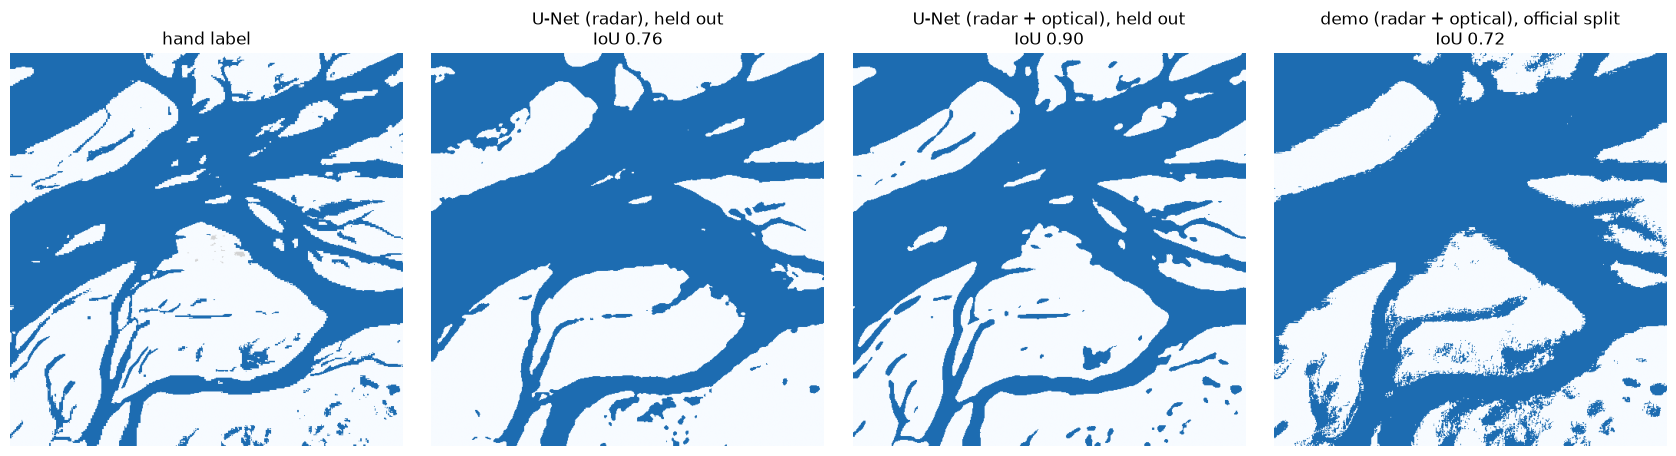

In [22]:
def held_out_map(slug, name):
    with np.load(RESULTS / "predictions" / f"{slug}.npz") as packed:
        bits = np.unpackbits(packed[name])[: config.CHIP_SIZE ** 2]
    return bits.reshape(config.CHIP_SIZE, config.CHIP_SIZE).astype(bool)


maps = {"U-Net (radar), held out": held_out_map("u_net_radar", CHIP_NAME),
        "U-Net (radar + optical), held out": held_out_map("u_net_radar_plus_optical", CHIP_NAME),
        "demo (radar + optical), official split": demo_mask}
fig, axes = plt.subplots(1, 4, figsize=(17, 4.4))
show_mask(axes[0], chip.label == 1, "hand label", chip.label)
for ax, (title, m) in zip(axes[1:], maps.items()):
    iou = evaluation.Confusion().add(m, chip.label).iou
    show_mask(ax, m, f"{title}\nIoU {iou:.2f}")
    print(f"{title:<40} IoU {iou:.3f}")
plt.tight_layout(); plt.show()

**What to notice:** on this chip the held-out radar + optical U-Net (IoU about 0.90) beats the held-out
radar U-Net (about 0.76), and both beat the one-minute demo (about 0.72), even though the demo was the only
one of the three trained with India chips. Training time and data volume matter more here than having seen
the flood.

## 10. Recap and exercises

**What happens, end to end, for a U-Net:**

| Step | Function (`unet.py` unless noted) |
|---|---|
| chip → normalised input | `data.model_input` |
| crops, rotations, flips | `ChipDataset(augment=True)` |
| the network | `build_unet` (ResNet-34 encoder, ImageNet-pretrained, via `smp.Unet`) |
| loss for rare water | `BceDiceLoss` |
| training, best epoch on validation | `train_unet` |
| whole-chip map | `predict_probability` (tiled) → `unet_predictor` (≥ 0.5) |
| scoring | `evaluation.evaluate` |
| saving / loading weights | `save_unet`, `load_unet` (used by `scripts/train.py`) |

**Reproduce the full run** (writes to `models/` and `results/`): `python scripts/train.py --stage unet`
(official split) and `python scripts/cross_event.py --stage unet` (leave-one-event-out, about 4 hours).

**Exercises** (all in memory):

1. **Radar only.** Train the demo with `"s1"` instead of `"s1s2"`. How much lower is its test IoU?
2. **More training.** Use 128 training chips or 16 epochs. Does the validation curve keep rising?
3. **No pretraining.** Build the demo with random starting weights: before training, run
   `unet.build_unet = lambda v, pretrained=False: _build_unet_original(v, pretrained=False)`, then train.
   Compare the first epochs' validation IoU. (Restore with `unet.build_unet = _build_unet_original`.)
4. **Threshold.** Score `unet.unet_predictor(demo_net, "s1s2", threshold=0.3)` and `0.7` on the example chip.
   What happens to precision and recall?
5. **BCE only.** Write a loss class that returns only the BCE part of `BceDiceLoss` and train with it (copy
   `train_unet` into a cell and change `loss_fn`). Does the model find less water?

In [23]:
print(f"notebook finished in {(time.time() - NOTEBOOK_STARTED) / 60:.1f} min")
assert "lightgbm" not in sys.modules

notebook finished in 1.3 min
